# Лабораторная работа 4. Бинарная классификация

Цель — построить модели бинарной классификации (логистическая регрессия, SVM, CART) и сравнить их качество.

### Задание 1
Импортировать датасет для бинарной классификации, т.е. целевой признак должен быть бинарным.

Используем набор **Bank Loan Defaulter** (`Bankloan.csv`): данные о клиентах банка, целевой признак `default` — факт невозврата кредита (1 — дефолт, 0 — кредит возвращён).

> **Подсказка к заданию 1.**
> - **Что делаем.** Загружаем таблицу `Bankloan.csv` и смотрим, что в ней: сколько строк и столбцов, какие типы данных (`info`), какие числа (`describe`).
> - **Целевой признак** — то, что модель будет предсказывать (`default`: вернул клиент кредит или нет). **Бинарный** значит, что у него всего два значения: 0 и 1. Если значений больше двух, это уже не бинарная классификация.
> - **Пропуски в `default`.** `NaN` — это пустая ячейка. У 450 клиентов не известно, вернули они кредит или нет, учиться на них нельзя.
> - **Баланс классов.** Смотрим, какая доля клиентов в каждом классе (74% / 26%). Если один класс сильно реже, модель может «ленится» и всегда отвечать про большинство. Поэтому позже нужны не только accuracy, но и precision / recall.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)

df = pd.read_csv('data/Bankloan.csv')
print('Размер датасета (строк, столбцов):', df.shape)
df.head()

Размер датасета (строк, столбцов): (1150, 9)


,age,ed,employ,address,income,debtinc,creddebt,othdebt,default
0,41,3,17,12,176,9.3,11.359392,5.008608,1.0
1,27,1,10,6,31,17.3,1.362202,4.000798,0.0
2,40,1,15,14,55,5.5,0.856075,2.168925,0.0
3,41,1,15,14,120,2.9,2.658720,0.821280,0.0
4,24,2,2,0,28,17.3,1.787436,3.056564,1.0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1150 entries, 0 to 1149
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1150 non-null   int64  
 1   ed        1150 non-null   int64  
 2   employ    1150 non-null   int64  
 3   address   1150 non-null   int64  
 4   income    1150 non-null   int64  
 5   debtinc   1150 non-null   float64
 6   creddebt  1150 non-null   float64
 7   othdebt   1150 non-null   float64
 8   default   700 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 81.0 KB


Описание признаков: `age` — возраст, `ed` — уровень образования (1–5), `employ` — стаж на текущем месте работы (лет), `address` — стаж проживания по текущему адресу (лет), `income` — доход (тыс.), `debtinc` — отношение долга к доходу (%), `creddebt` — долг по кредитным картам (тыс.), `othdebt` — прочие долги (тыс.), `default` — целевой признак.

In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,1150.0,35.24,8.09,20.00,29.00,35.00,41.00,56.00
ed,1150.0,1.70,0.93,1.00,1.00,1.00,2.00,5.00
employ,1150.0,8.78,6.91,0.00,3.00,7.00,13.00,33.00
address,1150.0,8.49,6.98,0.00,3.00,7.00,12.00,34.00
income,1150.0,47.98,40.51,13.00,24.00,36.00,56.75,446.00
debtinc,1150.0,10.06,6.58,0.10,5.20,8.75,13.60,41.30
creddebt,1150.0,1.61,2.14,0.01,0.42,0.90,1.90,20.56
othdebt,1150.0,3.10,3.53,0.05,1.05,2.04,3.86,35.20
default,700.0,0.26,0.44,0.00,0.00,0.00,1.00,1.00


Проверим, что целевой признак бинарный, и посмотрим распределение классов.

Уникальные значения default: [0.0, 1.0]
Пропусков в default: 450 из 1150
default
0.0    517
NaN    450
1.0    183
Name: count, dtype: int64

Доля классов среди размеченных объектов:
default
0.0    0.739
1.0    0.261
Name: proportion, dtype: float64


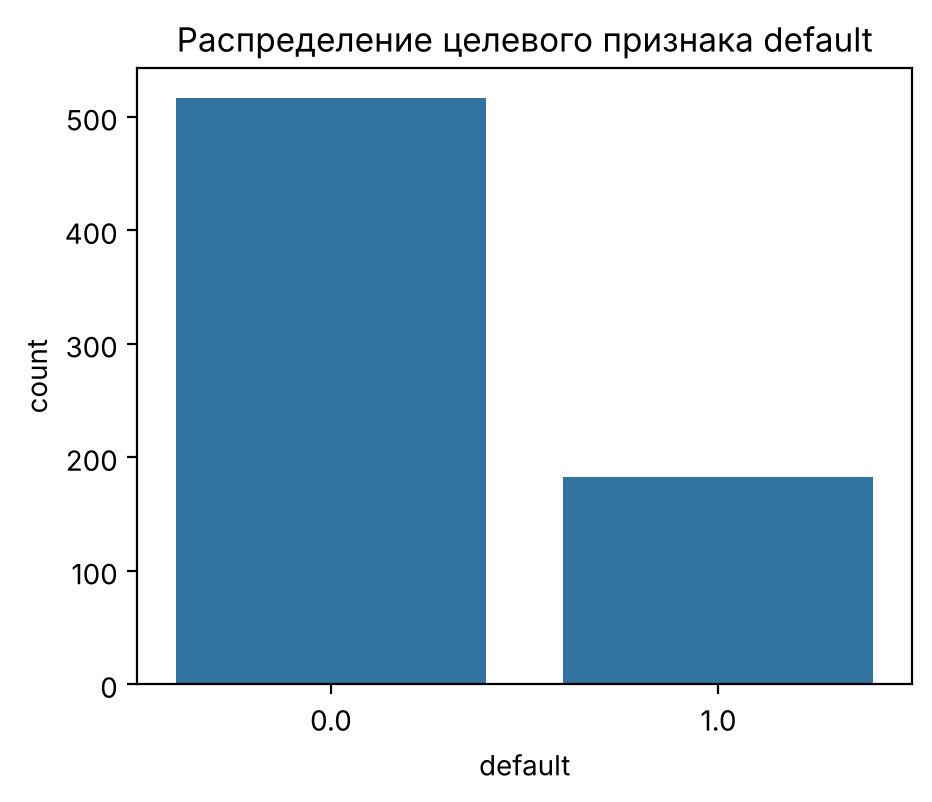

In [4]:
print('Уникальные значения default:', sorted(df['default'].dropna().unique().tolist()))
print('Пропусков в default:', df['default'].isna().sum(), 'из', len(df))

counts = df['default'].value_counts(dropna=False)
print(counts)
print('\nДоля классов среди размеченных объектов:')
print(df['default'].value_counts(normalize=True).round(3))

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x='default')
plt.title('Распределение целевого признака default')
plt.show()

**Итог по заданию 1.** Датасет загружен: 1150 объектов, 8 числовых признаков и целевой признак `default`, который принимает только значения 0 и 1, то есть задача — бинарная классификация. У 450 объектов значение целевого признака отсутствует (неразмеченные клиенты): для обучения и оценки моделей они непригодны, этот вопрос решим в задании 2 при очистке данных. Среди 700 размеченных объектов классы несбалансированы: дефолт у 26% клиентов (183 из 700), что учтём при оценке качества (использовать не только accuracy, но и precision, recall, F1).

### Задание 2
Очистить датасет от пропусков и выбросов, если они есть, выполнить нормализацию либо стандартизацию данных, если необходимо.

**2.1. Пропуски и дубликаты.**

> **Подсказка к заданию 2: очистка данных.**
> - **Пропуски и дубликаты.** Пропуск — пустая ячейка, дубликат — полностью одинаковая строка. Целевой признак заполнять «средним» нельзя (получится выдуманная метка), поэтому строки без него удаляем.
> - **Выброс** — значение, сильно выбивающееся из остальных (например, доход 446 при типичных 30–50). **Правило IQR:** IQR — это ширина «середины» данных (Q3 − Q1). Всё, что дальше чем 1.5·IQR от краёв середины, считаем выбросом. На **boxplot** («ящик с усами») выбросы видны как точки за усами.
> - **Винзоризация** (`clip`): экстремальные значения не удаляем, а «подрезаем» до границы. Так мы не теряем строки, а влияние выбросов становится меньше.
> - **Стандартизация** приводит признаки к одной шкале (среднее 0, разброс 1). Она нужна логистической регрессии и SVM, потому что они чувствительны к масштабу. Дереву решений она не нужна.
> - **Как проверить результат.** После обработки пропусков и дубликатов должно быть 0, значения должны лежать в границах, а у стандартизованных признаков среднее 0 и std 1.

Пропусков по столбцам:
age           0
ed            0
employ        0
address       0
income        0
debtinc       0
creddebt      0
othdebt       0
default     450
dtype: int64

Полных дубликатов: 300
Дубликатов среди объектов с пустым default: 300


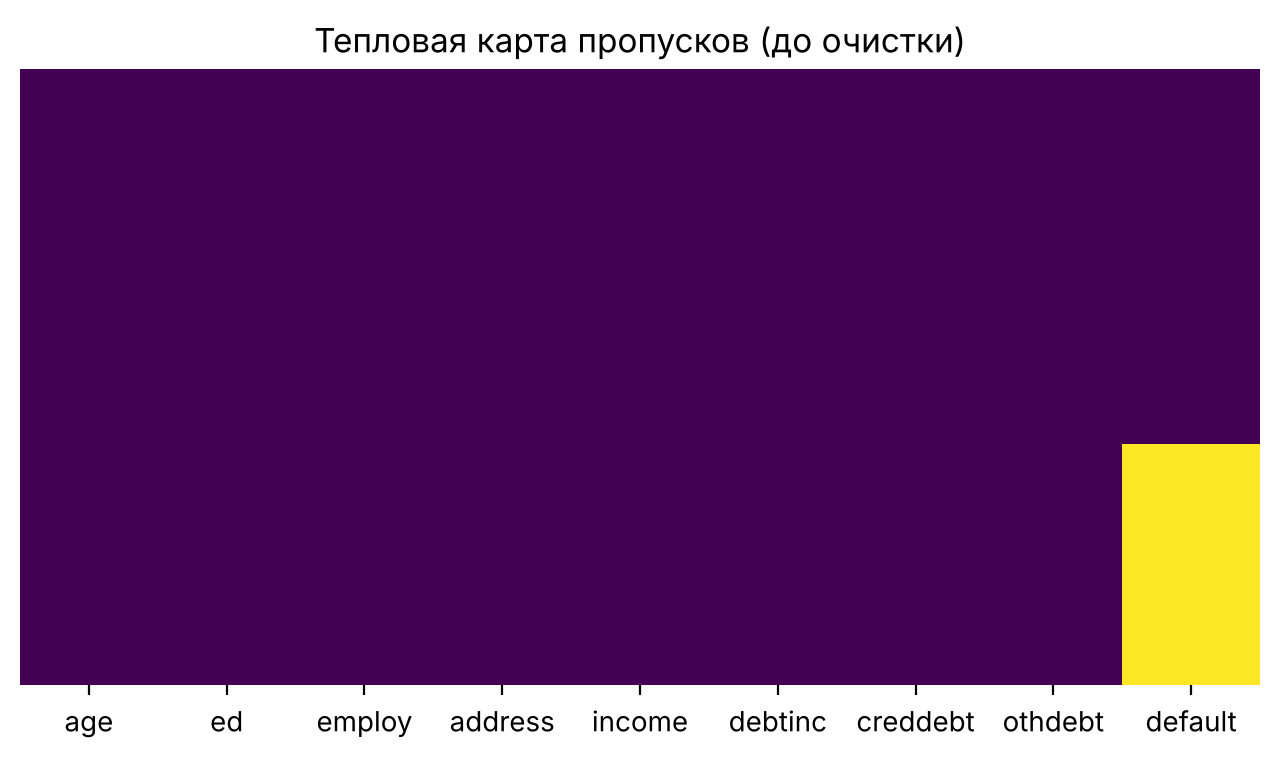

In [5]:
print('Пропусков по столбцам:')
print(df.isna().sum())
print('\nПолных дубликатов:', df.duplicated().sum())
print('Дубликатов среди объектов с пустым default:', df[df['default'].isna()].duplicated().sum())

plt.figure(figsize=(8, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Тепловая карта пропусков (до очистки)')
plt.show()

Пропуски есть только в целевом признаке (450 объектов), все признаки заполнены. Значение целевой переменной нельзя восстановить (заполнение медианой или модой исказило бы метки), а такие объекты нельзя использовать ни для обучения, ни для оценки качества, поэтому их удаляем. Заодно уходят и все 300 полных дубликатов: они приходились целиком на неразмеченные строки.

In [6]:
df_clean = df.dropna(subset=['default']).copy()
df_clean['default'] = df_clean['default'].astype(int)
df_clean = df_clean.reset_index(drop=True)

print('Размер после удаления неразмеченных объектов:', df_clean.shape)
print('Пропусков:', df_clean.isna().sum().sum(), ' Дубликатов:', df_clean.duplicated().sum())

Размер после удаления неразмеченных объектов: (700, 9)
Пропусков: 0  Дубликатов: 0


**2.2. Выбросы.** Смотрим на BoxPlot и считаем выбросы по правилу межквартильного размаха (IQR): значения за пределами $[Q_1 - 1.5\,IQR,\; Q_3 + 1.5\,IQR]$. Бинарный целевой признак и порядковый `ed` (категории 1–5) не проверяем.

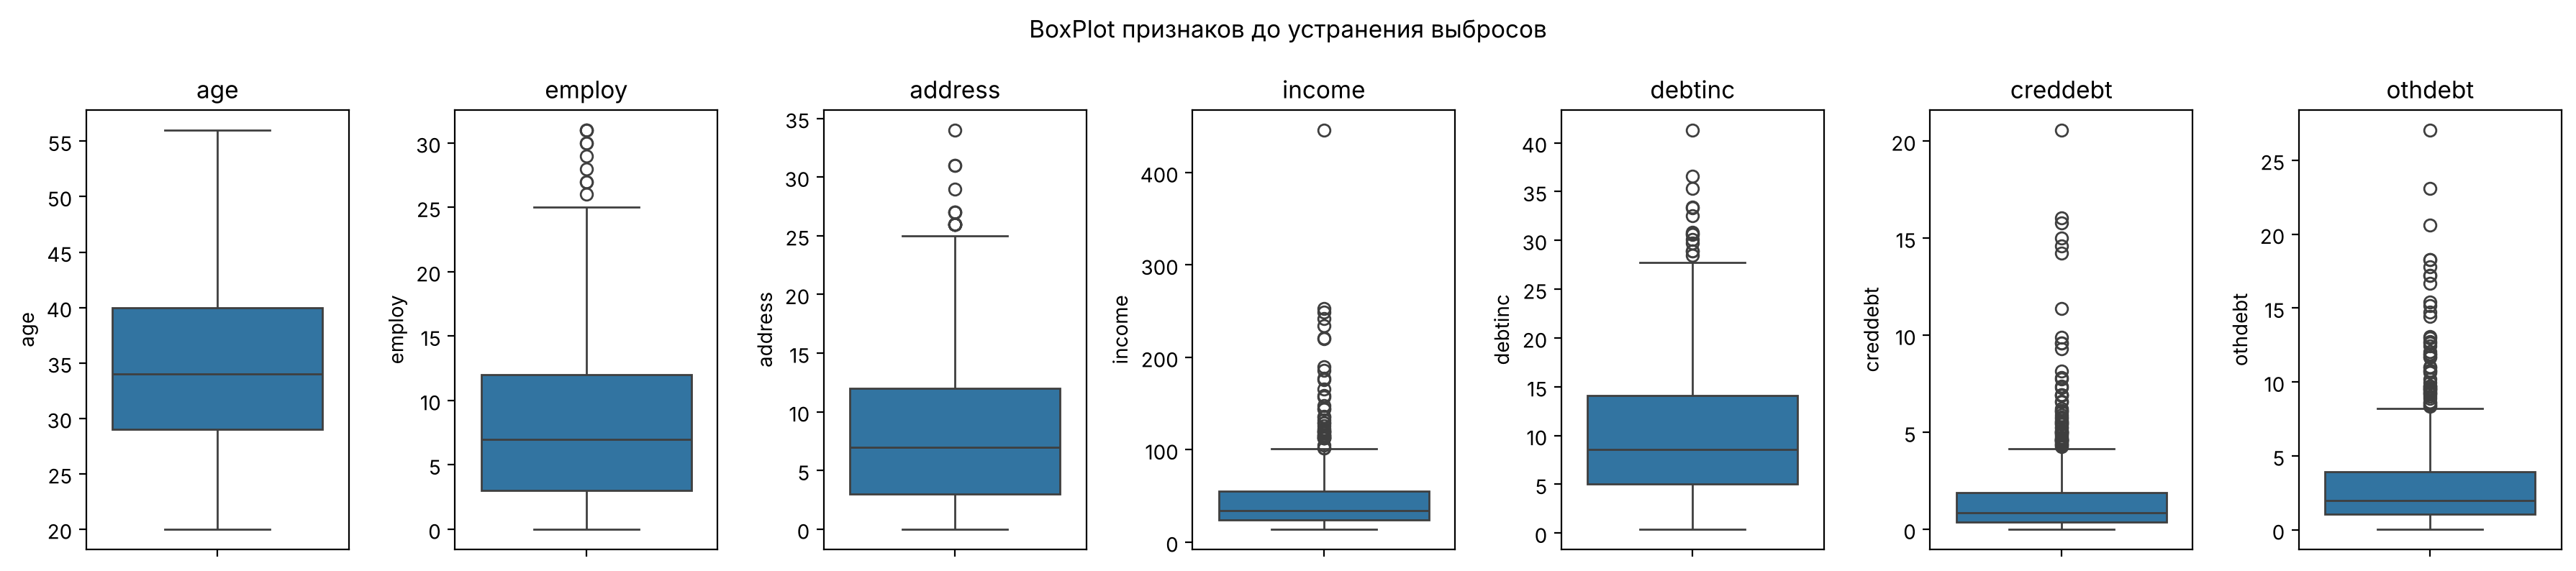

,признак,нижняя граница,верхняя граница,выбросов,"доля, %"
0,age,12.50,56.50,0,0.0
1,employ,-10.50,25.50,10,1.4
2,address,-10.50,25.50,14,2.0
3,income,-22.50,101.50,40,5.7
4,debtinc,-8.69,27.81,14,2.0
5,creddebt,-1.93,4.20,55,7.9
6,othdebt,-3.27,8.24,48,6.9


In [7]:
num_cols = ['age', 'employ', 'address', 'income', 'debtinc', 'creddebt', 'othdebt']

fig, axes = plt.subplots(1, len(num_cols), figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(col)
fig.suptitle('BoxPlot признаков до устранения выбросов')
plt.tight_layout()
plt.show()

bounds = {}
rows = []
for col in num_cols:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    bounds[col] = (low, high)
    n_out = int(((df_clean[col] < low) | (df_clean[col] > high)).sum())
    rows.append({'признак': col, 'нижняя граница': round(low, 2), 'верхняя граница': round(high, 2),
                 'выбросов': n_out, 'доля, %': round(100 * n_out / len(df_clean), 1)})
pd.DataFrame(rows)

Выбросы есть в `employ`, `address`, `income`, `debtinc`, `creddebt`, `othdebt`; все они только сверху (длинный правый хвост: у небольшого числа клиентов очень высокие доходы и долги). Таких объектов от 1.4% до 7.9%, а выборка небольшая (700), поэтому удалять строки нецелесообразно (потеряем часть информации и ещё сильнее сократим выборку, в том числе объекты миноритарного класса). Вместо этого ограничим значения границами IQR (винзоризация): экстремальные значения заменяются ближайшей границей.

Все значения лежат в допустимых границах.


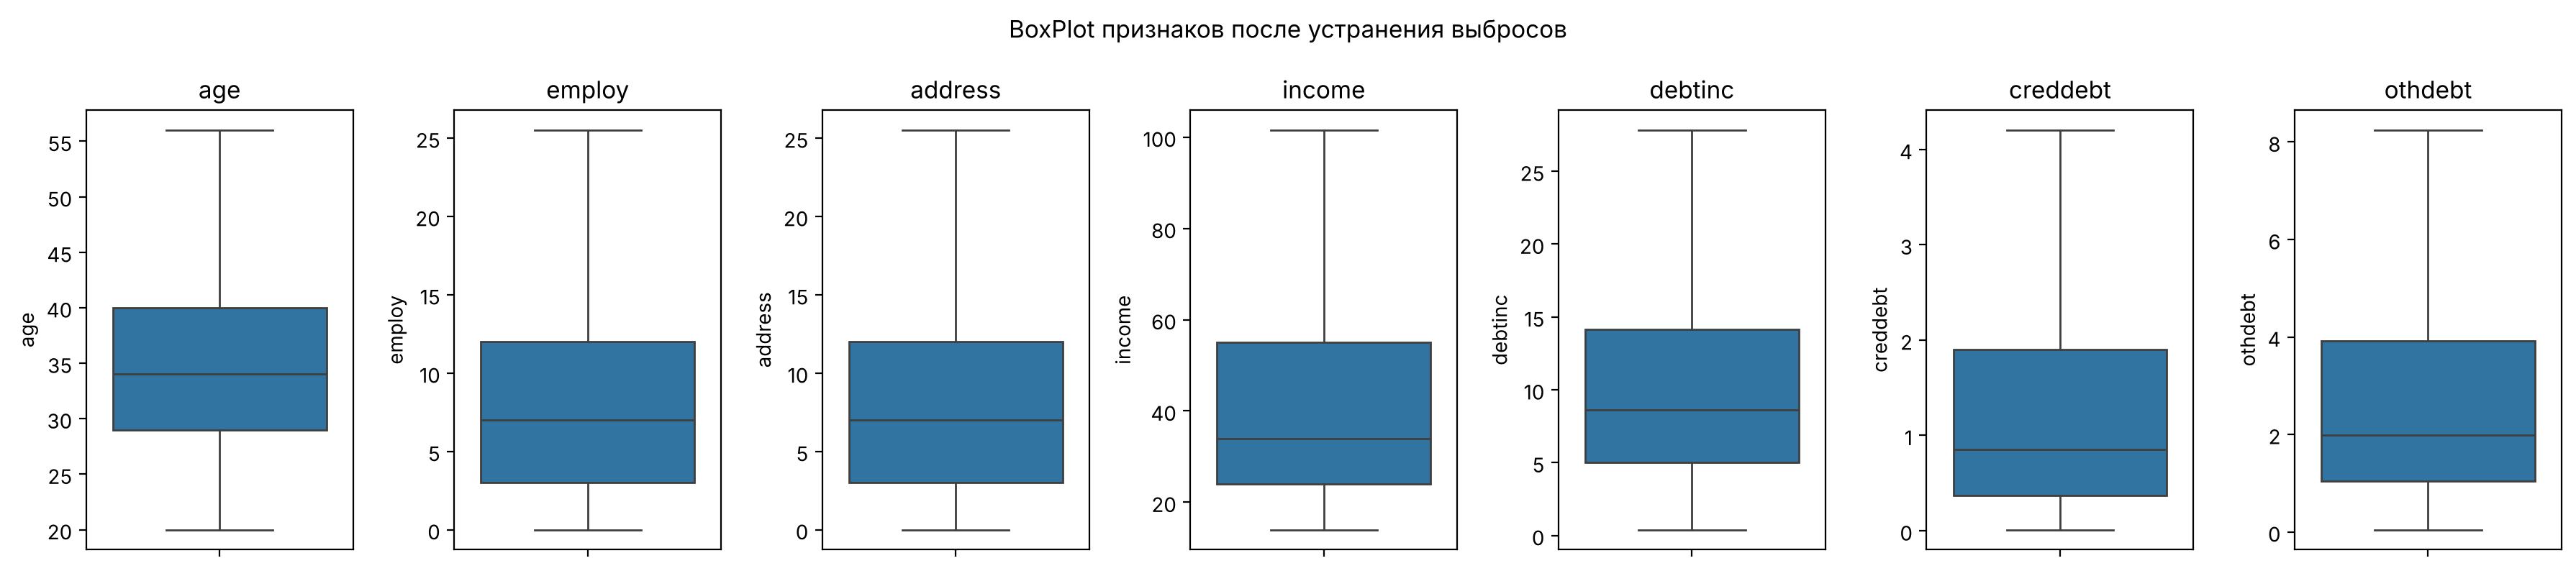

,count,mean,std,min,25%,50%,75%,max
age,700.0,34.86,8.00,20.00,29.00,34.00,40.00,56.00
employ,700.0,8.34,6.51,0.00,3.00,7.00,12.00,25.50
address,700.0,8.23,6.70,0.00,3.00,7.00,12.00,25.50
income,700.0,42.48,24.39,14.00,24.00,34.00,55.00,101.50
debtinc,700.0,10.17,6.55,0.40,5.00,8.60,14.12,27.81
creddebt,700.0,1.32,1.24,0.01,0.37,0.85,1.90,4.20
othdebt,700.0,2.77,2.31,0.05,1.04,1.99,3.92,8.24


In [8]:
df_no_out = df_clean.copy()
for col, (low, high) in bounds.items():
    df_no_out[col] = df_no_out[col].clip(lower=low, upper=high)

# проверка: после обработки все значения лежат внутри исходных границ IQR
for col, (low, high) in bounds.items():
    assert df_no_out[col].between(low, high).all()
print('Все значения лежат в допустимых границах.')

fig, axes = plt.subplots(1, len(num_cols), figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df_no_out[col], ax=ax)
    ax.set_title(col)
fig.suptitle('BoxPlot признаков после устранения выбросов')
plt.tight_layout()
plt.show()

df_no_out[num_cols].describe().T.round(2)

**2.3. Стандартизация.** Признаки имеют разные масштабы (например, `income` до ~100, `creddebt` до ~4), а логистическая регрессия и SVM чувствительны к масштабу (SVM с RBF-ядром считает расстояния между объектами). Поэтому приведём признаки к нулевому среднему и единичному стандартному отклонению (`StandardScaler`). Для дерева решений CART масштабирование не нужно, но и не вредит. Целевой признак не масштабируем.

Среднее признаков: {'age': 0.0, 'ed': -0.0, 'employ': -0.0, 'address': -0.0, 'income': -0.0, 'debtinc': -0.0, 'creddebt': -0.0, 'othdebt': -0.0}
Std признаков:     {'age': 1.0, 'ed': 1.0, 'employ': 1.0, 'address': 1.0, 'income': 1.0, 'debtinc': 1.0, 'creddebt': 1.0, 'othdebt': 1.0}


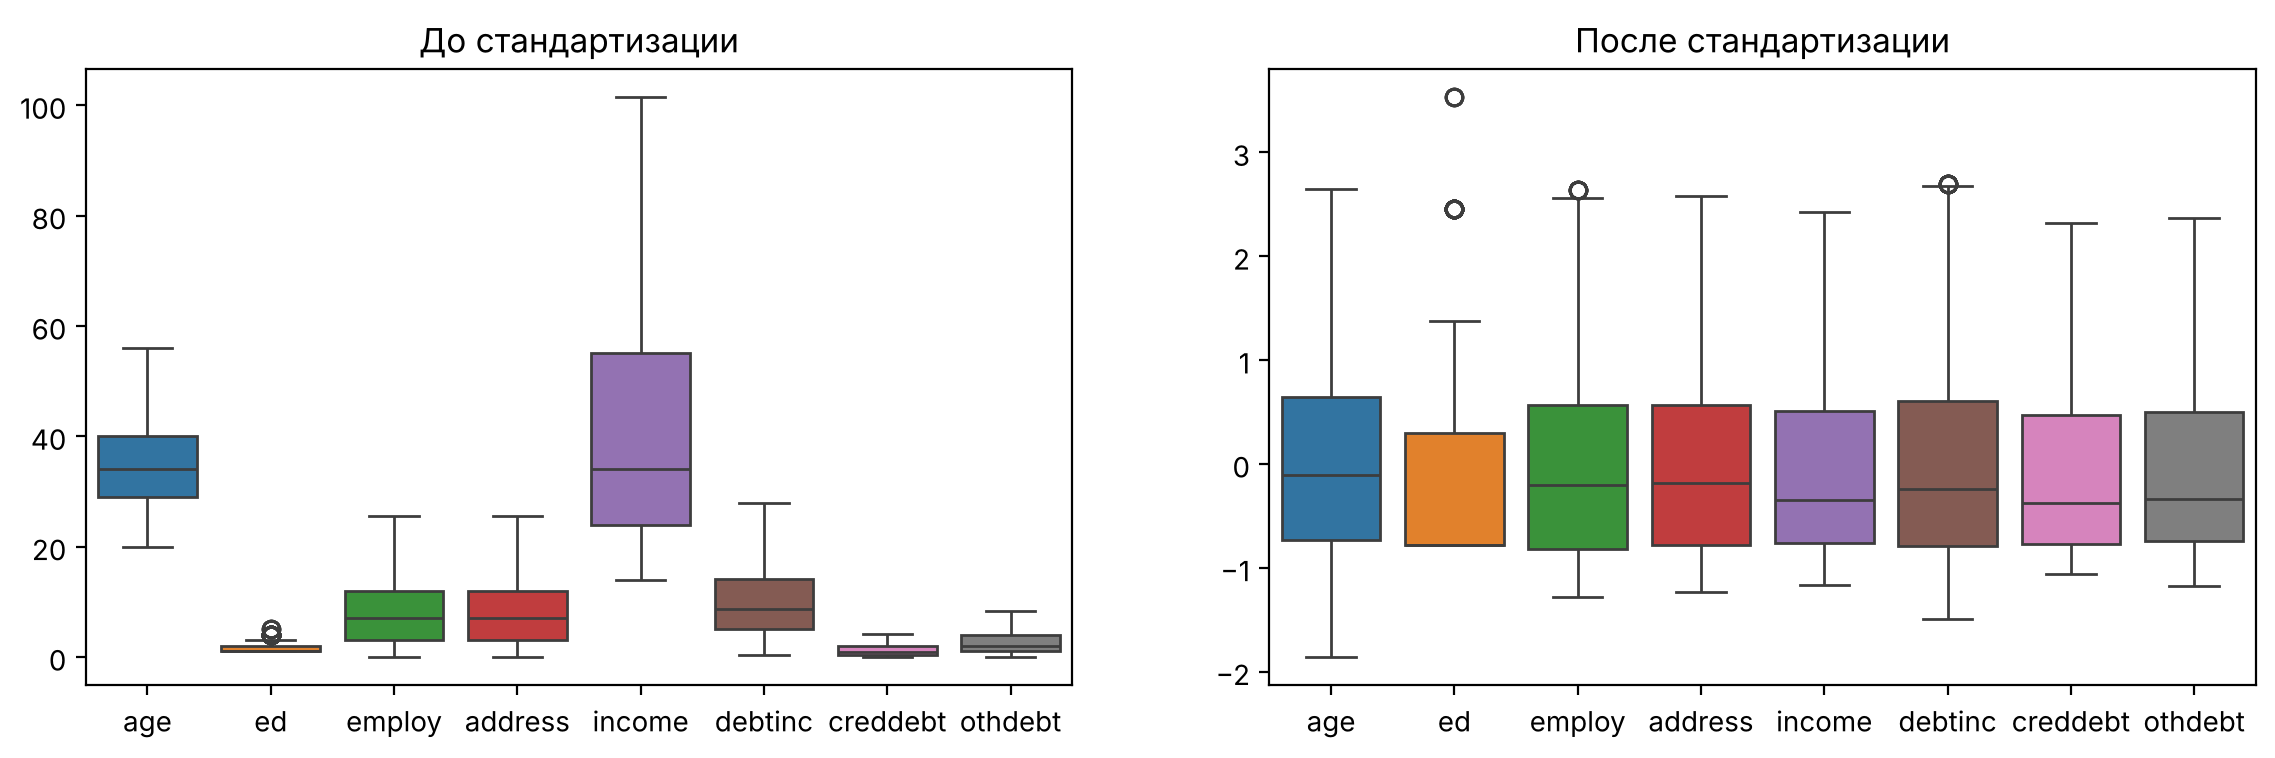

In [9]:
from sklearn.preprocessing import StandardScaler

feature_cols = [c for c in df_no_out.columns if c != 'default']
scaler = StandardScaler()
df_scaled = df_no_out.copy()
df_scaled[feature_cols] = scaler.fit_transform(df_no_out[feature_cols])

print('Среднее признаков:', df_scaled[feature_cols].mean().round(6).to_dict())
print('Std признаков:    ', df_scaled[feature_cols].std(ddof=0).round(6).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df_no_out[feature_cols], ax=axes[0])
axes[0].set_title('До стандартизации')
sns.boxplot(data=df_scaled[feature_cols], ax=axes[1])
axes[1].set_title('После стандартизации')
plt.show()

**Итог по заданию 2.** Удалены 450 неразмеченных объектов (вместе с 300 дубликатами), осталось 700 объектов без пропусков. Выбросы в шести признаках ограничены границами IQR без потери строк, признаки стандартизованы.

Примечание: здесь стандартизация выполнена на всей выборке, чтобы показать результат. При обучении моделей (задание 4) скалер будет обучаться только на обучающей части внутри `Pipeline`, чтобы информация из тестовой выборки не попадала в обучение.

### Задание 3
Выбрать целевую переменную и сформировать набор признаков.

**Целевая переменная:** `default` (1 — клиент не вернул кредит, 0 — вернул). **Признаки-кандидаты:** остальные 8 столбцов. Оценим их связь с целевой переменной и между собой, чтобы обосновать состав признаков.

> **Подсказка к заданию 3.**
> - **Целевая переменная** `y` — то, что предсказываем (`default`). **Признаки** `X` — всё, по чему предсказываем (остальные 8 столбцов). Правило: в признаках не должно быть ничего, что «подсказывает» ответ (утечка данных).
> - **Корреляция** `r` показывает силу линейной связи двух величин: от −1 до +1. Знак задаёт направление (плюс: чем больше признак, тем чаще дефолт), величина показывает силу (0 — связи нет). Тепловая карта корреляций — это таблица таких чисел, выведенная цветом.
> - **Зачем смотреть корреляции между признаками.** Если два признака почти дублируют друг друга, одного достаточно. У нас связи умеренные, поэтому оставили все 8.
> - **Train / test.** Обучающая часть (560 объектов) нужна, чтобы модель училась, тестовая (140) — чтобы честно проверить её на данных, которых она не видела.
> - **`stratify=y`** сохраняет долю классов (26% дефолтов) и в train, и в test. Без этого в тест могло бы случайно попасть слишком мало «редких» объектов.

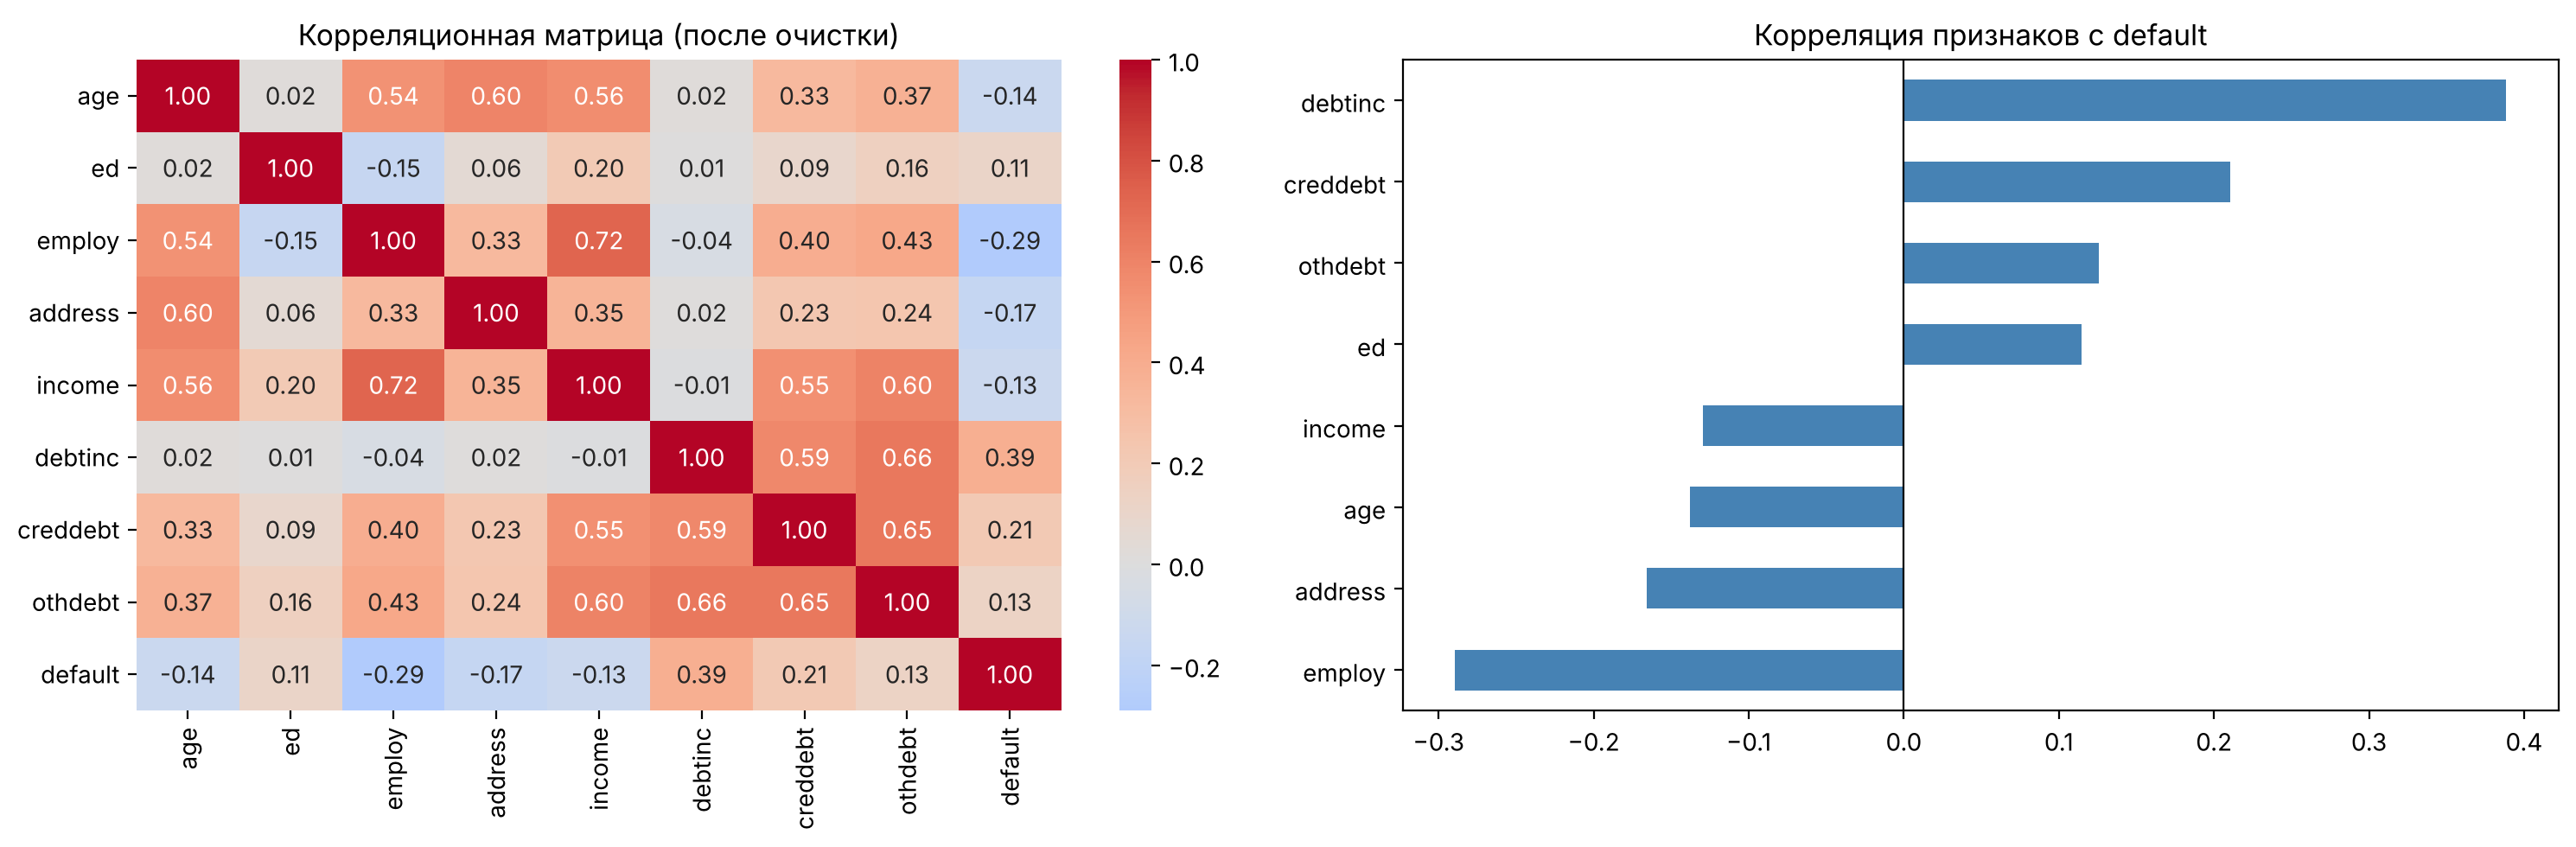

employ     -0.289
address    -0.166
age        -0.138
income     -0.129
ed          0.115
othdebt     0.126
creddebt    0.210
debtinc     0.388
Name: default, dtype: float64


In [10]:
corr = df_no_out.corr()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[0])
axes[0].set_title('Корреляционная матрица (после очистки)')

target_corr = corr['default'].drop('default').sort_values()
target_corr.plot(kind='barh', ax=axes[1], color='steelblue')
axes[1].set_title('Корреляция признаков с default')
axes[1].axvline(0, color='k', lw=0.8)
plt.tight_layout()
plt.show()

print(target_corr.round(3))

In [11]:
# пары сильно коррелирующих признаков (|r| > 0.5), кроме целевой переменной
feat_corr = corr.drop(index='default', columns='default')
pairs = [(a, b, round(feat_corr.loc[a, b], 2))
         for i, a in enumerate(feat_corr.columns) for b in feat_corr.columns[i + 1:]
         if abs(feat_corr.loc[a, b]) > 0.5]
pd.DataFrame(pairs, columns=['признак 1', 'признак 2', 'корреляция'])

,признак 1,признак 2,корреляция
0,age,employ,0.54
1,age,address,0.60
2,age,income,0.56
3,employ,income,0.72
4,income,creddebt,0.55
5,income,othdebt,0.60
6,debtinc,creddebt,0.59
7,debtinc,othdebt,0.66
8,creddebt,othdebt,0.65


**Выводы по заданию 3.**

- Целевая переменная — `default`. Остальные 8 столбцов используем как признаки: ни один из них не вычисляется из целевой переменной, утечки данных нет.
- Все признаки хотя бы слабо связаны с целевой переменной: сильнее всего `debtinc` (r = 0.39, чем выше долговая нагрузка, тем чаще дефолт) и `employ` (r = −0.29, чем больше стаж, тем реже дефолт); самые слабые — `ed`, `othdebt`, `income` (|r| ≈ 0.12–0.13). Линейная связь — лишь один из видов зависимости, а модели (особенно SVM с RBF-ядром и CART) способны использовать и нелинейные, поэтому слабокоррелирующие признаки не исключаем.
- Между признаками есть умеренная корреляция (наибольшая — `employ` и `income`, r = 0.72; долговые показатели `debtinc`, `creddebt`, `othdebt` связаны между собой на уровне 0.59–0.66). Она ниже порога, при котором мультиколлинеарность становится критичной, при этом признаков всего 8 и каждый несёт свою информацию, поэтому оставляем все 8.
- Выборку делим на обучающую и тестовую (80/20, `random_state=42`). Из-за несбалансированности классов (26% дефолтов) используем стратификацию по целевой переменной: доля дефолта в обеих частях одинакова (≈0.26). Получилось 560 объектов в train и 140 в test.

In [12]:
from sklearn.model_selection import train_test_split

target = 'default'
features = [c for c in df_no_out.columns if c != target]

X = df_no_out[features]
y = df_no_out[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print('Признаки:', features)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Доля дефолта: всего %.3f, train %.3f, test %.3f' % (y.mean(), y_train.mean(), y_test.mean()))

Признаки: ['age', 'ed', 'employ', 'address', 'income', 'debtinc', 'creddebt', 'othdebt']
Train: (560, 8)  Test: (140, 8)
Доля дефолта: всего 0.261, train 0.261, test 0.264


### Задание 4
Создать модель бинарной классификации на основе логистической регрессии, SVM и CART.

Каждую модель оформляем как `Pipeline`: для логистической регрессии и SVM первым шагом идёт `StandardScaler` (он обучается только на обучающей части), для дерева CART масштабирование не нужно. Из-за дисбаланса классов (26% дефолтов) во всех моделях используем `class_weight='balanced'`: ошибки на редком классе штрафуются сильнее. Гиперпараметры подбираем по сетке на обучающей выборке с 5-кратной стратифицированной кросс-валидацией (метрика — F1 по классу дефолта), тестовую выборку при этом не трогаем.

> **Подсказка к заданию 4: три модели.**
> - **Логистическая регрессия** — линейная модель. Она считает взвешенную сумму признаков и превращает её в вероятность дефолта (от 0 до 1). Граница между классами прямая.
> - **SVM** (метод опорных векторов) — проводит границу так, чтобы зазор до ближайших объектов обоих классов был максимальным. С ядром RBF граница может быть искривлённой. Ключевые параметры: `C` (насколько строго штрафуем ошибки) и `gamma` (насколько «извилистая» граница).
> - **CART** — дерево решений: набор вопросов «признак ≤ порога?», по которым объект «спускается» к ответу. Параметры `max_depth` (глубина) и `min_samples_leaf` (минимум объектов в листе) не дают дереву переобучиться.
> - **`Pipeline`** связывает шаги (масштабирование, затем модель) в одну цепочку. Тогда скейлер учится только на train и не «подсматривает» в тест.
> - **`class_weight='balanced'`**: ошибки на редком классе (дефолт) штрафуются сильнее, чтобы модель не игнорировала должников.
> - **`GridSearchCV`** перебирает варианты гиперпараметров. Каждый вариант проверяется **кросс-валидацией**: train делится на 5 частей, модель по очереди учится на четырёх и проверяется на пятой. Выбирается вариант с лучшим F1. Тест при этом не трогаем.

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    'Логистическая регрессия': (
        Pipeline([('scaler', StandardScaler()),
                  ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE))]),
        {'clf__C': [0.01, 0.1, 1, 10, 100]},
    ),
    'SVM (RBF)': (
        Pipeline([('scaler', StandardScaler()),
                  ('clf', SVC(kernel='rbf', class_weight='balanced', random_state=RANDOM_STATE))]),
        {'clf__C': [0.1, 1, 10, 100], 'clf__gamma': ['scale', 0.01, 0.1, 1]},
    ),
    'CART': (
        Pipeline([('clf', DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE))]),
        {'clf__max_depth': [2, 3, 4, 5, 7, None], 'clf__min_samples_leaf': [1, 5, 10, 20]},
    ),
}

fitted = {}
rows = []
for name, (pipe, grid) in models.items():
    gs = GridSearchCV(pipe, grid, scoring='f1', cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    fitted[name] = gs.best_estimator_
    rows.append({'модель': name, 'лучшие параметры': gs.best_params_, 'F1 (CV, train)': round(gs.best_score_, 3)})
pd.DataFrame(rows)

,модель,лучшие параметры,"F1 (CV, train)"
0,Логистическая регрессия,{'clf__C': 10},0.596
1,SVM (RBF),"{'clf__C': 1, 'clf__gamma': 0.1}",0.601
2,CART,"{'clf__max_depth': 3, 'clf__min_samples_leaf':...",0.542


### Задание 5
Оценить качество моделей.

Метрики считаем на тестовой выборке (140 объектов), которая не участвовала ни в обучении, ни в подборе гиперпараметров. Положительный класс — дефолт (1). Из-за дисбаланса accuracy неинформативна сама по себе: модель, всегда предсказывающая «дефолта нет», получила бы accuracy ≈ 0.74, но не нашла бы ни одного должника. Поэтому смотрим ещё precision, recall, F1 и ROC-AUC.

> **Подсказка к заданию 5: как читать метрики.**
> - **Матрица ошибок** — таблица 2×2: TN (верно «не дефолт»), FP (ошибочно «дефолт»), FN (пропущенный должник), TP (верно найденный должник).
> - **Accuracy** — доля верных ответов. При дисбалансе вводит в заблуждение: можно получить 74%, всегда отвечая «дефолта нет».
> - **Precision** — из тех, кого модель назвала должниками, какая доля действительно должники (насколько можно доверять тревоге).
> - **Recall** — из всех настоящих должников, какую долю модель нашла (сколько не пропустила).
> - **F1** — среднее (гармоническое) precision и recall. Высокий F1 бывает только при хороших обеих метриках.
> - **ROC-кривая и AUC.** Кривая показывает, как меняется доля найденных должников при росте числа ложных тревог. AUC — площадь под ней: 0.5 значит «как случайное угадывание», 1.0 — идеал. Чем кривая ближе к левому верхнему углу, тем лучше.
> - **Главный вывод.** Между precision и recall всегда есть компромисс, и «лучшая» модель зависит от того, что для банка дороже: пропустить должника или отказать хорошему клиенту.

In [14]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve)

def get_scores(model, X):
    # непрерывная оценка принадлежности к классу 1 для ROC-AUC
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

rows = []
for name, model in fitted.items():
    pred = model.predict(X_test)
    rows.append({
        'модель': name,
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred),
        'recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, get_scores(model, X_test)),
    })
results = pd.DataFrame(rows).set_index('модель').round(3)
print('Базовая accuracy (всегда «нет дефолта»):', round(1 - y_test.mean(), 3))
results

Базовая accuracy (всегда «нет дефолта»): 0.736


,accuracy,precision,recall,F1,ROC-AUC
модель,,,,,
Логистическая регрессия,0.721,0.481,0.703,0.571,0.835
SVM (RBF),0.671,0.437,0.838,0.574,0.816
CART,0.793,0.574,0.838,0.681,0.832


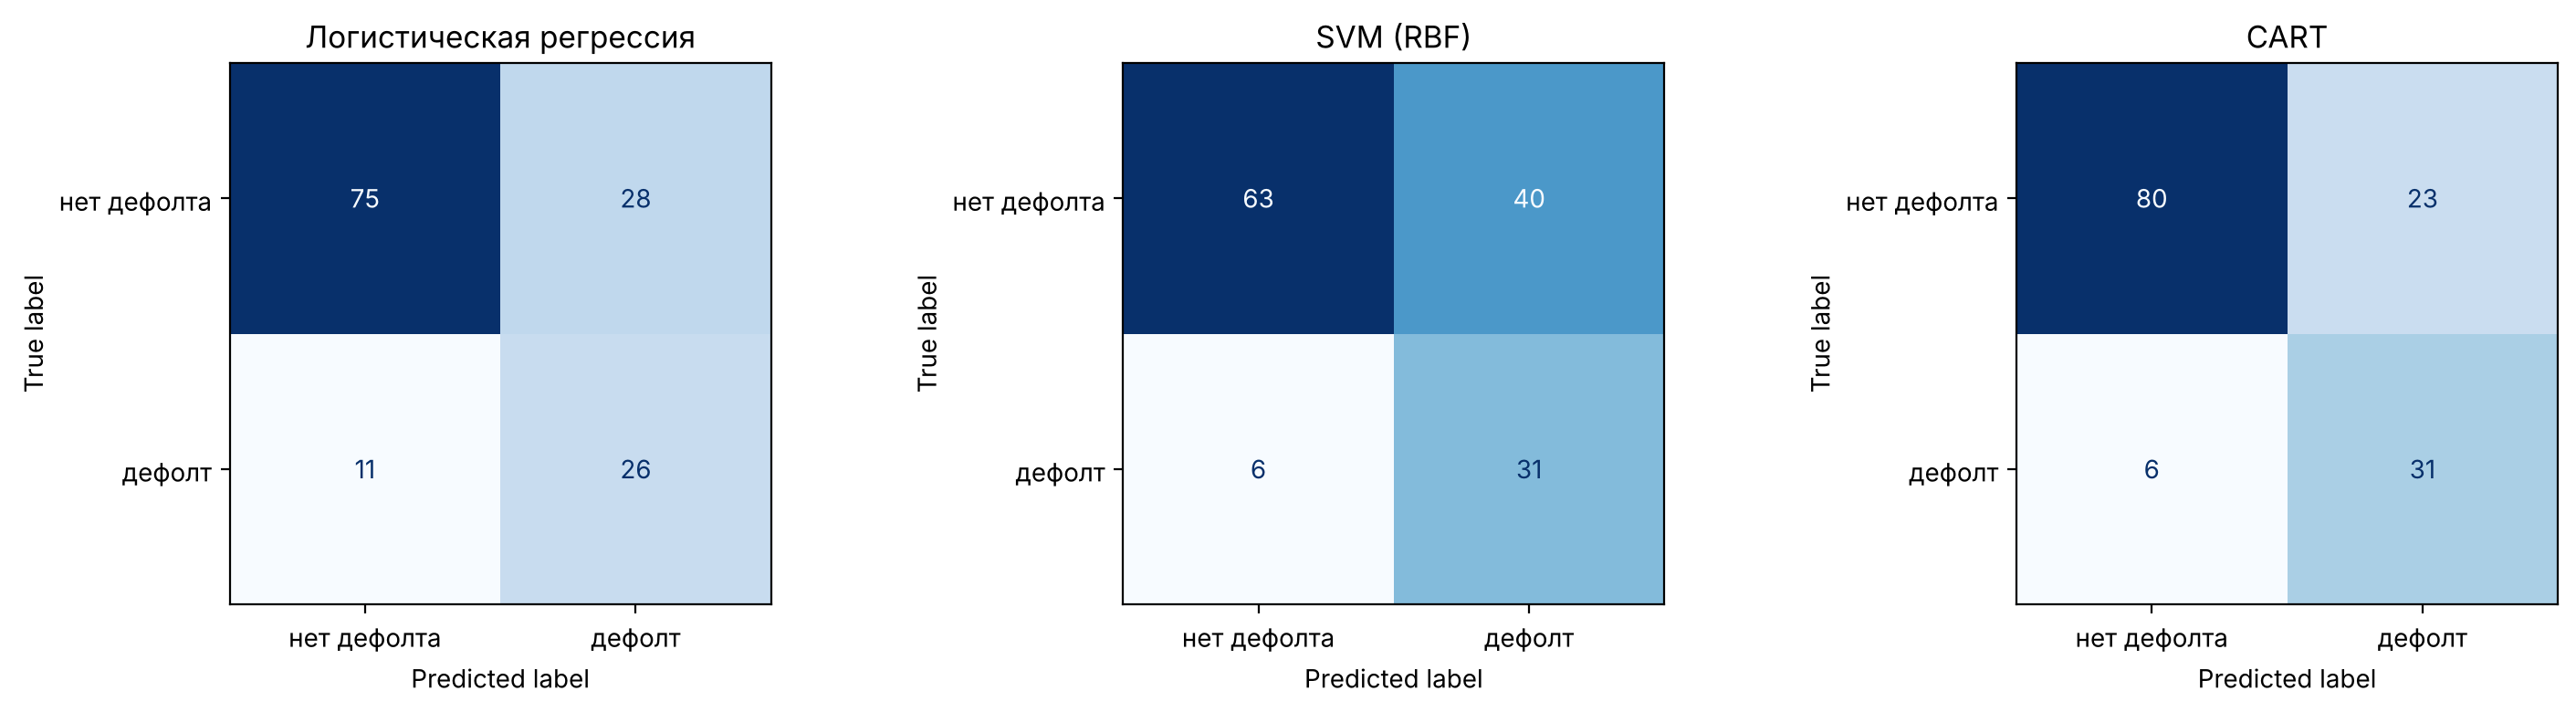

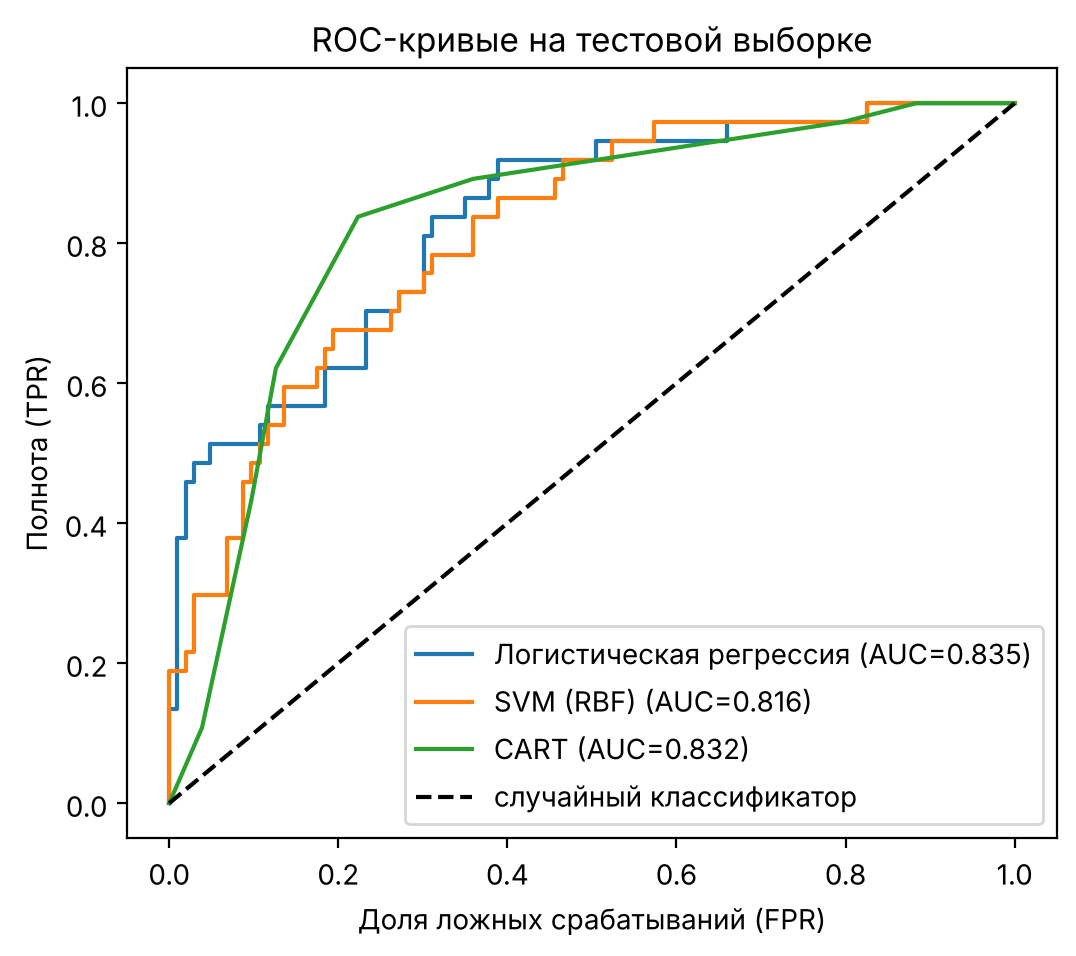

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=['нет дефолта', 'дефолт'],
                                          cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
for name, model in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, get_scores(model, X_test))
    plt.plot(fpr, tpr, label=f"{name} (AUC={results.loc[name, 'ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='случайный классификатор')
plt.xlabel('Доля ложных срабатываний (FPR)')
plt.ylabel('Полнота (TPR)')
plt.title('ROC-кривые на тестовой выборке')
plt.legend()
plt.show()

**Выводы по заданию 5.**

- **Лучшая по тестовым метрикам — CART** (глубина 3, не менее 20 объектов в листе): accuracy 0.793, precision 0.574, recall 0.838, F1 0.681. Из 37 должников в тесте он нашёл 31, при этом ложно отметил 23 из 103 добросовестных клиентов.
- **Логистическая регрессия:** F1 0.571, recall 0.703 (26 из 37), но больше всего ошибок среди «нормальных» клиентов после SVM (28 ложных срабатываний). Зато у неё лучший ROC-AUC (0.835), то есть ранжирует клиентов по риску не хуже остальных; по этому показателю CART (0.832) и SVM (0.816) практически не отстают.
- **SVM (RBF)** находит больше всех должников (recall 0.838, как и CART), но ценой самой низкой precision (0.437): 40 ложных срабатываний из 103.
- **Accuracy у логистической регрессии (0.721) и SVM (0.671) ниже базовой 0.736**, которую даёт «всегда предсказывать отсутствие дефолта». Это следствие `class_weight='balanced'`: модели сознательно жертвуют долей верных ответов ради полноты по редкому классу, тогда как константный классификатор не находит ни одного должника (recall = 0). Поэтому качество нужно оценивать по precision/recall/F1, а не по accuracy.
- **Осторожность с ранжированием.** В тесте только 37 объектов положительного класса: одна лишняя верная классификация меняет recall на ≈2.7 п.п., поэтому разница в F1 между моделями статистически ненадёжна. Показательно, что по кросс-валидации на train CART был худшим (F1 0.542 против 0.596 у логистической регрессии и 0.601 у SVM), а на тесте стал лучшим. Уверенно можно утверждать лишь, что все три модели заметно лучше случайного угадывания (AUC 0.82–0.84), а качество упирается в данные: малую выборку и умеренную связь признаков с целью.
- **Практический выбор:** если важнее не пропустить должника (цена ложного одобрения кредита выше цены отказа), подходят CART и SVM с recall 0.84; если важнее не отказывать добросовестным клиентам, лучше выбрать CART как модель с наиболее высокой precision, либо повысить порог у логистической регрессии. CART здесь ещё и самая интерпретируемая модель (глубина 3).

**Общий вывод по лабораторной.** Подготовленные данные (удалены неразмеченные строки и дубликаты, выбросы ограничены по IQR, признаки стандартизованы внутри `Pipeline`) позволили построить три модели бинарной классификации; все они сопоставимы по качеству (ROC-AUC ≈ 0.82–0.84), различаясь компромиссом между precision и recall.